# `ammico` workshop November 2026: comparing models with OpenRouter

*Delia Dumitrescu, Inga Ulusoy, Dmitrii Kapitan*

With `ammico`, you can analyze text on images and image content at the same time, see https://ssciwr.github.io/AMMICO/. In this notebook, we run the same analysis with several vision-language models hosted on [OpenRouter](https://openrouter.ai) and compare the results. First we start by importing the packages.

In [1]:
import openrouter_utils as OR

import ammico

This imports all the functionality from `ammico`. To analyze images, you can manually upload images to the Jupyter server; in this workshop, we will use pre-prepared datasets in `/home/jovyan/data_mounts/webdav`. The helper functions for running several models are in `openrouter_utils.py`, next to this notebook.

# Step 1: Read your data into AMMICO

`ammico` reads in files from a directory. You can iterate through directories in a recursive manner and filter by extensions. Note that the order of the files may vary on different OS. Reading in these files creates a dictionary `image_dict`, with one entry per image file, containing the file path and filename. This dictionary is the main data structure that ammico operates on and is extended successively with each detector run as explained below.

For reading in the files, the ammico function `find_files` is used, with optional keywords:

| input key | input type | possible input values |
| --------- | ---------- | --------------------- |
`path` | `str` | the directory containing the image files (defaults to the location set by environment variable `AMMICO_DATA_HOME`) |
| `pattern` | `str\|list` | the file extensions to consider (defaults to "png", "jpg", "jpeg", "gif", "webp", "avif", "tiff") |
| `recursive` | `bool` | include subdirectories recursively (defaults to `True`) |
| `limit` | `int` | maximum number of files to read (defaults to `20`, for all images set to `None` or `-1`) |
| `random_seed` | `int` | the random seed for shuffling the images; applies when only a few images are read and the selection should be preserved (defaults to `None`) |

Since every model is billed per request on OpenRouter, you may want to start with a small number of images by setting `limit`. All models are run on exactly the same images.

In [2]:
# Define your data path
data_path = (
    "/home/jovyan/data_mounts/webdav/dataset_emotions/"  # the selected directory
)

# Find files and create the image dictionary
image_dict = ammico.find_files(
    path=data_path,
    limit=-1,  # Limit the number of files to process (optional)
)

# 2. Connect to the models

We will ask the same questions about the images to several vision-language models and compare their answers.

[OpenRouter](https://openrouter.ai) gives access to many hosted models (OpenAI, Google, Anthropic, Qwen, Meta, Mistral, ...) through a single **OpenAI-compatible API** and a single API key. You need an account and an API key, which you can create at [openrouter.ai/keys](https://openrouter.ai/keys). The key is read from the environment variable `OPENROUTER_API_KEY`; if it is not set, you are asked to enter it below. Do not write your API key directly into the notebook, in particular if you share the notebook with others!

**Privacy note:** with OpenRouter your images are sent to a third party (OpenRouter and the provider of the selected model). Do not use this setup for data that must not leave your institution.

Any model on OpenRouter that accepts images as input can be used, see the [OpenRouter model list](https://openrouter.ai/models?input_modalities=image), where you also see the price per token. The model id is the name shown on the model page, prefixed with the provider, for example `openai/gpt-4o-mini`. Add or remove model ids in the list below.

In [3]:
# Connect to OpenRouter (asks for the API key if OPENROUTER_API_KEY is not set)
OR.connect()

models = [
    "google/gemini-2.5-flash",
    "qwen/qwen2.5-vl-72b-instruct",
    "meta-llama/llama-4-maverick",
]

Enter your OpenRouter API key:  ········


Connected to OpenRouter (key starts with 'sk-or-v1').


Then, we create an instance of the Python class that handles the visual question answering task. It holds one `ammico.ImageSummaryDetector` per model, each working on its own copy of `image_dict`, so that the results of the different models do not overwrite each other.

Many models on OpenRouter are served from a pool shared between all users. When it is busy, the request is rejected with a **rate limit error** (`Error code: 429`); such requests are retried with increasing waiting times. To avoid the rate limit, the number of requests sent at the same time is limited by `max_parallel_images` and `max_parallel_requests` (one request per question); lower these numbers if you still see many rate limit errors. Reasoning models "think" before they answer, which can leave the answer empty, so reasoning is switched off (`disable_reasoning=True`).

In [4]:
image_summary_vqa = OR.MultiModelDetector(
    models,
    image_dict,
    max_parallel_images=4,  # images processed at the same time
    max_parallel_requests=2,  # requests (questions) per image at the same time
    disable_reasoning=True,
)

# 3. Run the content analysis: Visual question answering

Now we ask questions about the images. For this, provide a list of questions and pass it to the Python class that you have instantiated above. All models answer the same questions:

In [5]:
list_of_questions = [
    "Does the picture show any positive or negative emotional content?",
    "Does the picture show any positive or negative emotional content? Answer as applicable: positive, negative, both, none, or DK. Do not guess.",
    "Does the picture show any negative emotional content?",
    "Does the picture show any negative emotional content? Answer as applicable: yes, no or DK. Do not guess.",
    "Does the picture show any negative emotional content, either because of the facial or body displays of the individuals, or because of what it depicts, or because of the text it contains? Answer as applicable: yes, no or DK. Do not guess.",
    "Does the picture show any positive emotional content?",
    "Does the picture show any positive emotional content? Answer as applicable: yes, no or DK. Do not guess.",
    "Does the picture show any positive emotional content, either because of the facial and body displays of the individuals, or because of what it depicts, or because of the text it contains? Answer as applicable: yes, no or DK. Do not guess.",
]

In [6]:
answers = image_summary_vqa.analyse_images_from_dict(
    analysis_type="questions",
    list_of_questions=list_of_questions,
    is_concise_summary=True,
    is_concise_answer=True,
)

google/gemini-2.5-flash: running on 300 images ...
google/gemini-2.5-flash: done in 307.4 s
qwen/qwen2.5-vl-72b-instruct: running on 300 images ...
qwen/qwen2.5-vl-72b-instruct: done in 294.5 s
meta-llama/llama-4-maverick: running on 300 images ...
meta-llama/llama-4-maverick: done in 457.4 s


Again for your convenience we display the images and the answers of all models to the questions together below:

In [ ]:
OR.show_answers(answers, list_of_questions)

# 4. Export the results

To export the results for further processing, convert the image dictionaries of all models into one pandas dataframe. Each row corresponds to one image analyzed by one model; the column `model` tells you which model produced the result.

In [8]:
image_df = OR.get_dataframe(answers)

Inspect the dataframe:

In [9]:
image_df.head(5)

,model,filename,vqa
0,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_emotio...,[The picture shows **positive** emotional cont...
1,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_emotio...,[The picture shows **negative** emotional cont...
2,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_emotio...,[The picture shows **negative** emotional cont...
3,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_emotio...,[The picture shows **negative emotional conten...
4,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_emotio...,[The picture shows **negative** emotional cont...


Export the dataframe to a csv file, and additionally the results of each model to its own csv file (`<provider>__<model>.csv`):

In [10]:
image_df.to_csv("./emotions_data_out.csv")
OR.save_per_model(image_df, "./emotions_results")

google/gemini-2.5-flash: saved to emotions_results/google__gemini-2.5-flash.csv
qwen/qwen2.5-vl-72b-instruct: saved to emotions_results/qwen__qwen2.5-vl-72b-instruct.csv
meta-llama/llama-4-maverick: saved to emotions_results/meta-llama__llama-4-maverick.csv


# 5. Analyse the results
You can compare the results to the manual labels and observe how accurate the different VLMs capture the content.

# Question accuracy for several models

Which of several questions (prompts) gets the most images right for each model, and do the models agree on which question works best?

**How to use:** run the VQA with ammico on one of the course datasets and save the result as a csv file. Fill in the two paths in the next cell and run all cells. Tables and plots are saved in `comparison_results/` next to the (first) result file.

In [11]:
# ============ SETTINGS: the only cell you need to change ============
RESULTS_FILES = [  # csv file(s) with the model answers, one file per model
    "/home/jovyan/emotions_results/google__gemini-2.5-flash.csv",  # (or one file with several models); glob patterns work,
    "/home/jovyan/emotions_results/meta-llama__llama-4-maverick.csv",  # e.g. "../my_results/emotions_*.csv"
    "/home/jovyan/emotions_results/qwen__qwen2.5-vl-72b-instruct.csv",  # e.g. "../my_results/emotions_*.csv"
]
IMAGE_DIR = data_path  # folder with the images, here the same as above

**Datasets** – the dataset (emotions, politicians or symbols) is detected from the image names in the result file, so only the paths change. The paths are relative to this notebook.

The images can be in one flat folder; they are only needed for the image examples. Questions, ground truth and expected answers are defined in `DATASETS` in `vqa_eval_utils.py`; the ground-truth and question files are read from `ground_truth/` next to the image folder (or from the `*_output/` folders of the course repository). The answers must be to the questions in these files, in the same order.

## 5.1 Data and questions

In [12]:
import vqa_eval_utils as U

run = U.load(RESULTS_FILES, IMAGE_DIR, "question_accuracy_models")
U.show_questions(run)

dataset: emotions  |  models: gemini-2.5-flash, llama-4-maverick, qwen2.5-vl-72b-instruct
images: 300 in the results, 300 with ground truth, 300 found in /home/jovyan/data_mounts/webdav/dataset_emotions/
images answered completely by all models (used for the comparison): 300
output folder: /home/jovyan/emotions_results/comparison_results/question_accuracy_models


,type,style,question,expected answer (label -> answer)
qid,,,,
Q1,polarity,open,Does the picture show any positive or negative emotional content?,"positive -> positive, negative -> negative, neutral -> none"
Q2,polarity,constrained,"Does the picture show any positive or negative emotional content? Answer as applicable: positive, negative, both, none, or DK. Do not guess.","positive -> positive, negative -> negative, neutral -> none"
Q3,negative,open,Does the picture show any negative emotional content?,"positive -> no, negative -> yes, neutral -> no"
Q4,negative,constrained,"Does the picture show any negative emotional content? Answer as applicable: yes, no or DK. Do not guess.","positive -> no, negative -> yes, neutral -> no"
Q5,negative,constrained+cues,"Does the picture show any negative emotional content, either because of the facial or body displays of the individuals, or because of what it depicts, or because of the text it contains? Answer as...","positive -> no, negative -> yes, neutral -> no"
Q6,positive,open,Does the picture show any positive emotional content?,"positive -> yes, negative -> no, neutral -> no"
Q7,positive,constrained,"Does the picture show any positive emotional content? Answer as applicable: yes, no or DK. Do not guess.","positive -> yes, negative -> no, neutral -> no"
Q8,positive,constrained+cues,"Does the picture show any positive emotional content, either because of the facial and body displays of the individuals, or because of what it depicts, or because of the text it contains? Answer a...","positive -> yes, negative -> no, neutral -> no"


## 5.2 From free text to answers
Each answer is mapped to a category (yes / no / dk, …) by the rules of its question type. `exact`, `first` and `package_code` are safe; the keyword rules (`kw_*`) are heuristics, so read the sample of raw answers below against their `normalised` value. Only images answered by all models are used, so all models are compared on the same images.

In [13]:
U.show_normalisation(run)

answer_is  exact  first  kw_affirm  kw_both  kw_dk  kw_negated  kw_neutral  kw_none  kw_none_however  kw_opposite  kw_polarity  unparsed
qid model                                                                                                                                                            
Q1  gemini-2.5-flash                 0    109      6          0        0      0           0           2       71                3            0          109         0
    llama-4-maverick                 0      0      0          0        2      6           0          13       48                0            0          228         3
    qwen2.5-vl-72b-instruct          0    103      0          0        0      0           0           1       65                1            0          130         0
Q2  gemini-2.5-flash                 0    300      0          0        0      0           0           0        0                0            0            0         0
    llama-4-maverick                39    229      0          0        3      0           0           1        3                0            0           24         1
    qwen2.5-vl-72b-instruct          0    300      0          0        0      0           0           0        0                0            0            0         0
Q3  gemini-2.5-flash                 0      7    293          0        0      0           0           0        0                0            0            0         0
    llama-4-maverick                 5      5    105         47        0      1         135           0        0                0            2            0         0
    qwen2.5-vl-72b-instruct          0    279     21          0        0      0           0           0        0                0            0            0         0
Q4  gemini-2.5-flash                 0    300      0          0        0      0           0           0        0                0            0            0         0
    llama-4-maverick                 0    300      0          0        0      0           0           0        0                0            0            0         0
    qwen2.5-vl-72b-instruct          0    300      0          0        0      0           0           0        0                0            0            0         0
Q5  gemini-2.5-flash                 0    300      0          0        0      0           0           0        0                0            0            0         0
    llama-4-maverick                 2    295      0          2        0      0           1           0        0                0            0            0         0
    qwen2.5-vl-72b-instruct          0    300      0          0        0      0           0           0        0                0            0            0         0
Q6  gemini-2.5-flash                 0     26    273          0        0      1           0           0        0                0            0            0         0
    llama-4-maverick                 6      6     92         82        0      0         113           0        0                0            0            0         1
    qwen2.5-vl-72b-instruct          0    270     30          0        0      0           0           0        0                0            0            0         0
Q7  gemini-2.5-flash                 0    300      0          0        0      0           0           0        0                0            0            0         0
    llama-4-maverick                 0    299      0          0        0      0           1           0        0                0            0            0         0
    qwen2.5-vl-72b-instruct          0    300      0          0        0      0           0           0        0                0            0            0         0
Q8  gemini-2.5-flash                 0    300      0          0        0      0           0           0        0                0            0            0         0
    llama-4-maverick                 1    299

1021 distinct keyword-mapped or unparsed answers (all in /home/jovyan/emotions_results/comparison_results/question_accuracy_models/mapping_review.csv); sample:


,model,qid,rule,normalised,raw
411,llama-4-maverick,Q1,unparsed,unparsed,"The image depicts a man in a suit standing at a podium with microphones, suggesting a press conference or public address. The text at the bottom of the image is in Hungarian and appears to be a he..."
412,llama-4-maverick,Q1,unparsed,unparsed,"The image depicts a plane flying in the sky, with the sun shining through the clouds. The overall atmosphere is one of serenity and tranquility, evoking feelings of freedom and adventure. There ar..."
413,llama-4-maverick,Q1,unparsed,unparsed,"The image shows Olaf Scholz, the Chancellor of Germany, standing in front of flags and speaking into microphones. His facial expression and body language convey a sense of seriousness, but there i..."
484,llama-4-maverick,Q2,unparsed,unparsed,"The image depicts a man sitting at a table, intently examining a piece of paper while holding another in his hand. He is dressed in a denim jacket over a brown shirt and appears to be engaged in a..."
837,llama-4-maverick,Q6,unparsed,unparsed,"The image depicts a lion cub and a bird in a natural setting, with the two animals appearing to be interacting with each other. The overall atmosphere of the image is one of curiosity and innocenc..."
251,llama-4-maverick,Q1,kw_polarity,negative,"The image depicts a man with an open mouth and outstretched hand, conveying a sense of anger or frustration. The text at the bottom of the image is in Hungarian and translates to ""Didn't you know ..."
75,gemini-2.5-flash,Q1,kw_polarity,negative,"The picture shows **negative** emotional content. The woman's facial expression (furrowed brow, downturned mouth) suggests disgust or displeasure."
946,qwen2.5-vl-72b-instruct,Q1,kw_polarity,negative,"The picture shows negative emotional content. The individuals appear to be in distress, with one person covering their face and the other looking downcast, suggesting sadness or grief."
662,llama-4-maverick,Q6,kw_affirm,yes,"The image depicts three men posing together, with one of them placing his hand on the shoulder of another. The facial expressions of the individuals in the photograph suggest that they are experie..."
891,qwen2.5-vl-72b-instruct,Q1,kw_none,none,"The picture does not explicitly show positive or negative emotional content. It is an aerial view of a house with text overlay, which appears to be informative rather than emotionally charged. The..."


> **Result:** 300 images have results and a ground-truth label (label: number of images – positive: 99, negative: 99, neutral: 84, unclear: 18). 1153 of 7200 answers needed keyword rules and 5 remain unparsed.

## 5.3 Accuracy per question
**Accuracy** = share of images whose (normalised) answer matches the expected answer from the ground truth. DK, unclear and unparsed answers count as **wrong**; images without an expected answer (e.g. label `unclear`) are not scored.
The **majority baseline** is the accuracy of always giving the most frequent expected answer – a question is only useful if it beats it clearly. Error bars are 95% Wilson confidence intervals.

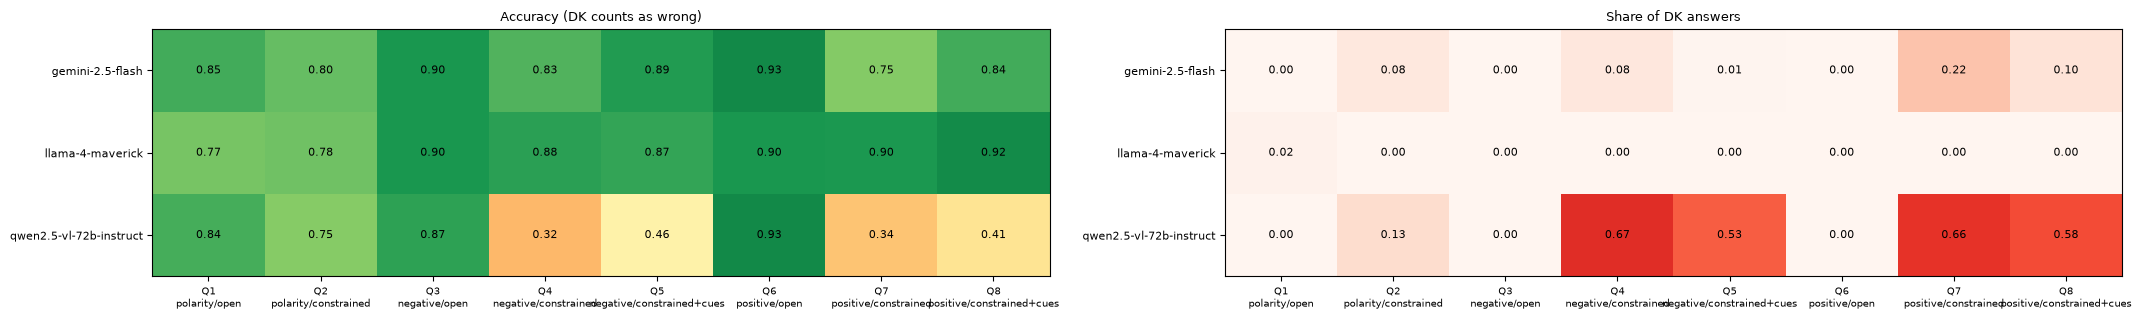

qid,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8
majority_baseline,0.351,0.351,0.649,0.649,0.649,0.649,0.649,0.649


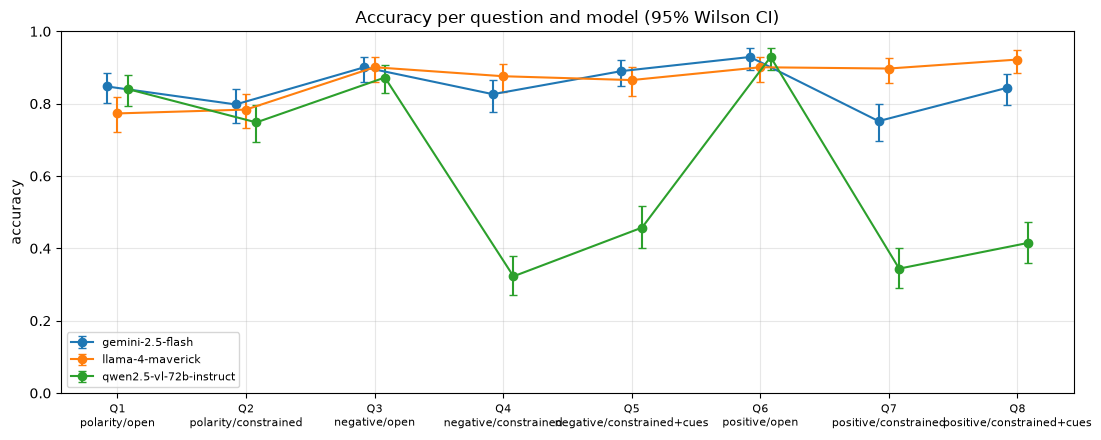

> **Result:** Accuracy range per model: gemini-2.5-flash 0.75–0.93 (best Q6), llama-4-maverick 0.77–0.92 (best Q8) and qwen2.5-vl-72b-instruct 0.32–0.93 (best Q6). The best combination is qwen2.5-vl-72b-instruct with Q6 (0.93). High DK shares lower the accuracy for qwen2.5-vl-72b-instruct Q4 (67%), qwen2.5-vl-72b-instruct Q7 (66%), qwen2.5-vl-72b-instruct Q8 (58%), qwen2.5-vl-72b-instruct Q5 (53%) and gemini-2.5-flash Q7 (22%).  The models agree most on Q3 (spread 0.03) and differ most on Q7 (spread 0.55 between the best and the worst model).

In [14]:
acc = U.show_accuracy(run)

## 5.4 Accuracy per image group
The same accuracy for each image group and model: a low value shows which kind of image makes a question fail.

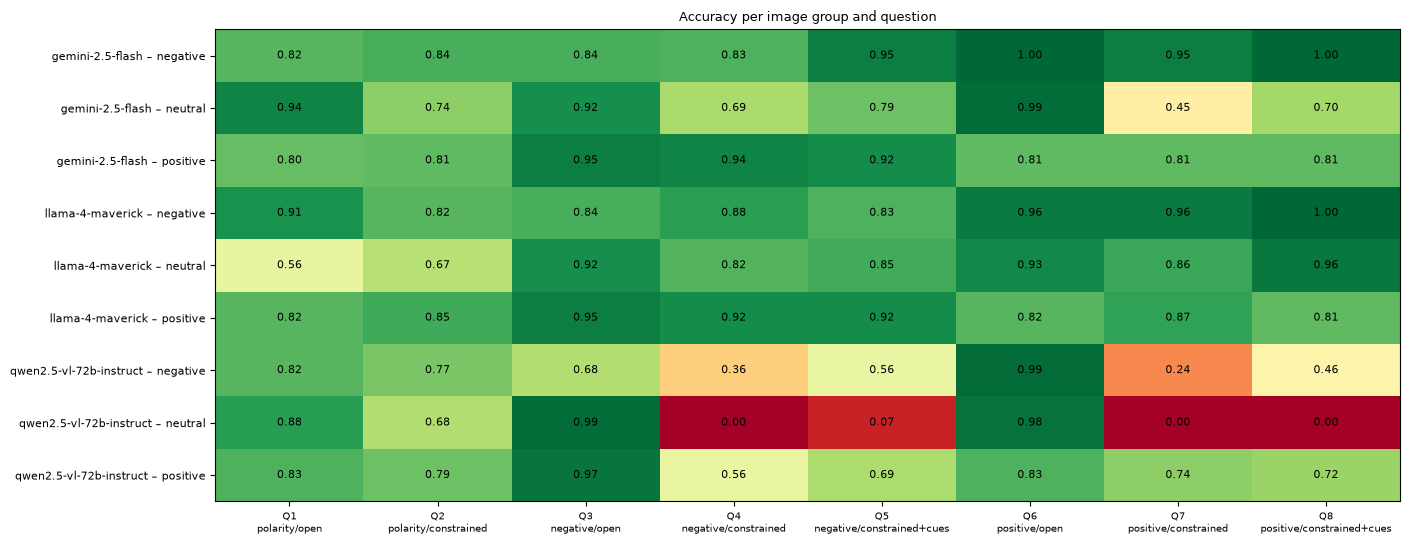

> **Result:** Weakest group and question per model – gemini-2.5-flash: neutral with Q7 (0.45), llama-4-maverick: neutral with Q1 (0.56) and qwen2.5-vl-72b-instruct: neutral with Q8 (0.00).

In [15]:
U.show_groups(run, acc)

## 5.5 Which differences between questions are significant?
Each pair of questions is compared on the same images with an exact McNemar test (Holm-corrected). Blue = the row question is more accurate, red = less accurate, * = significant.

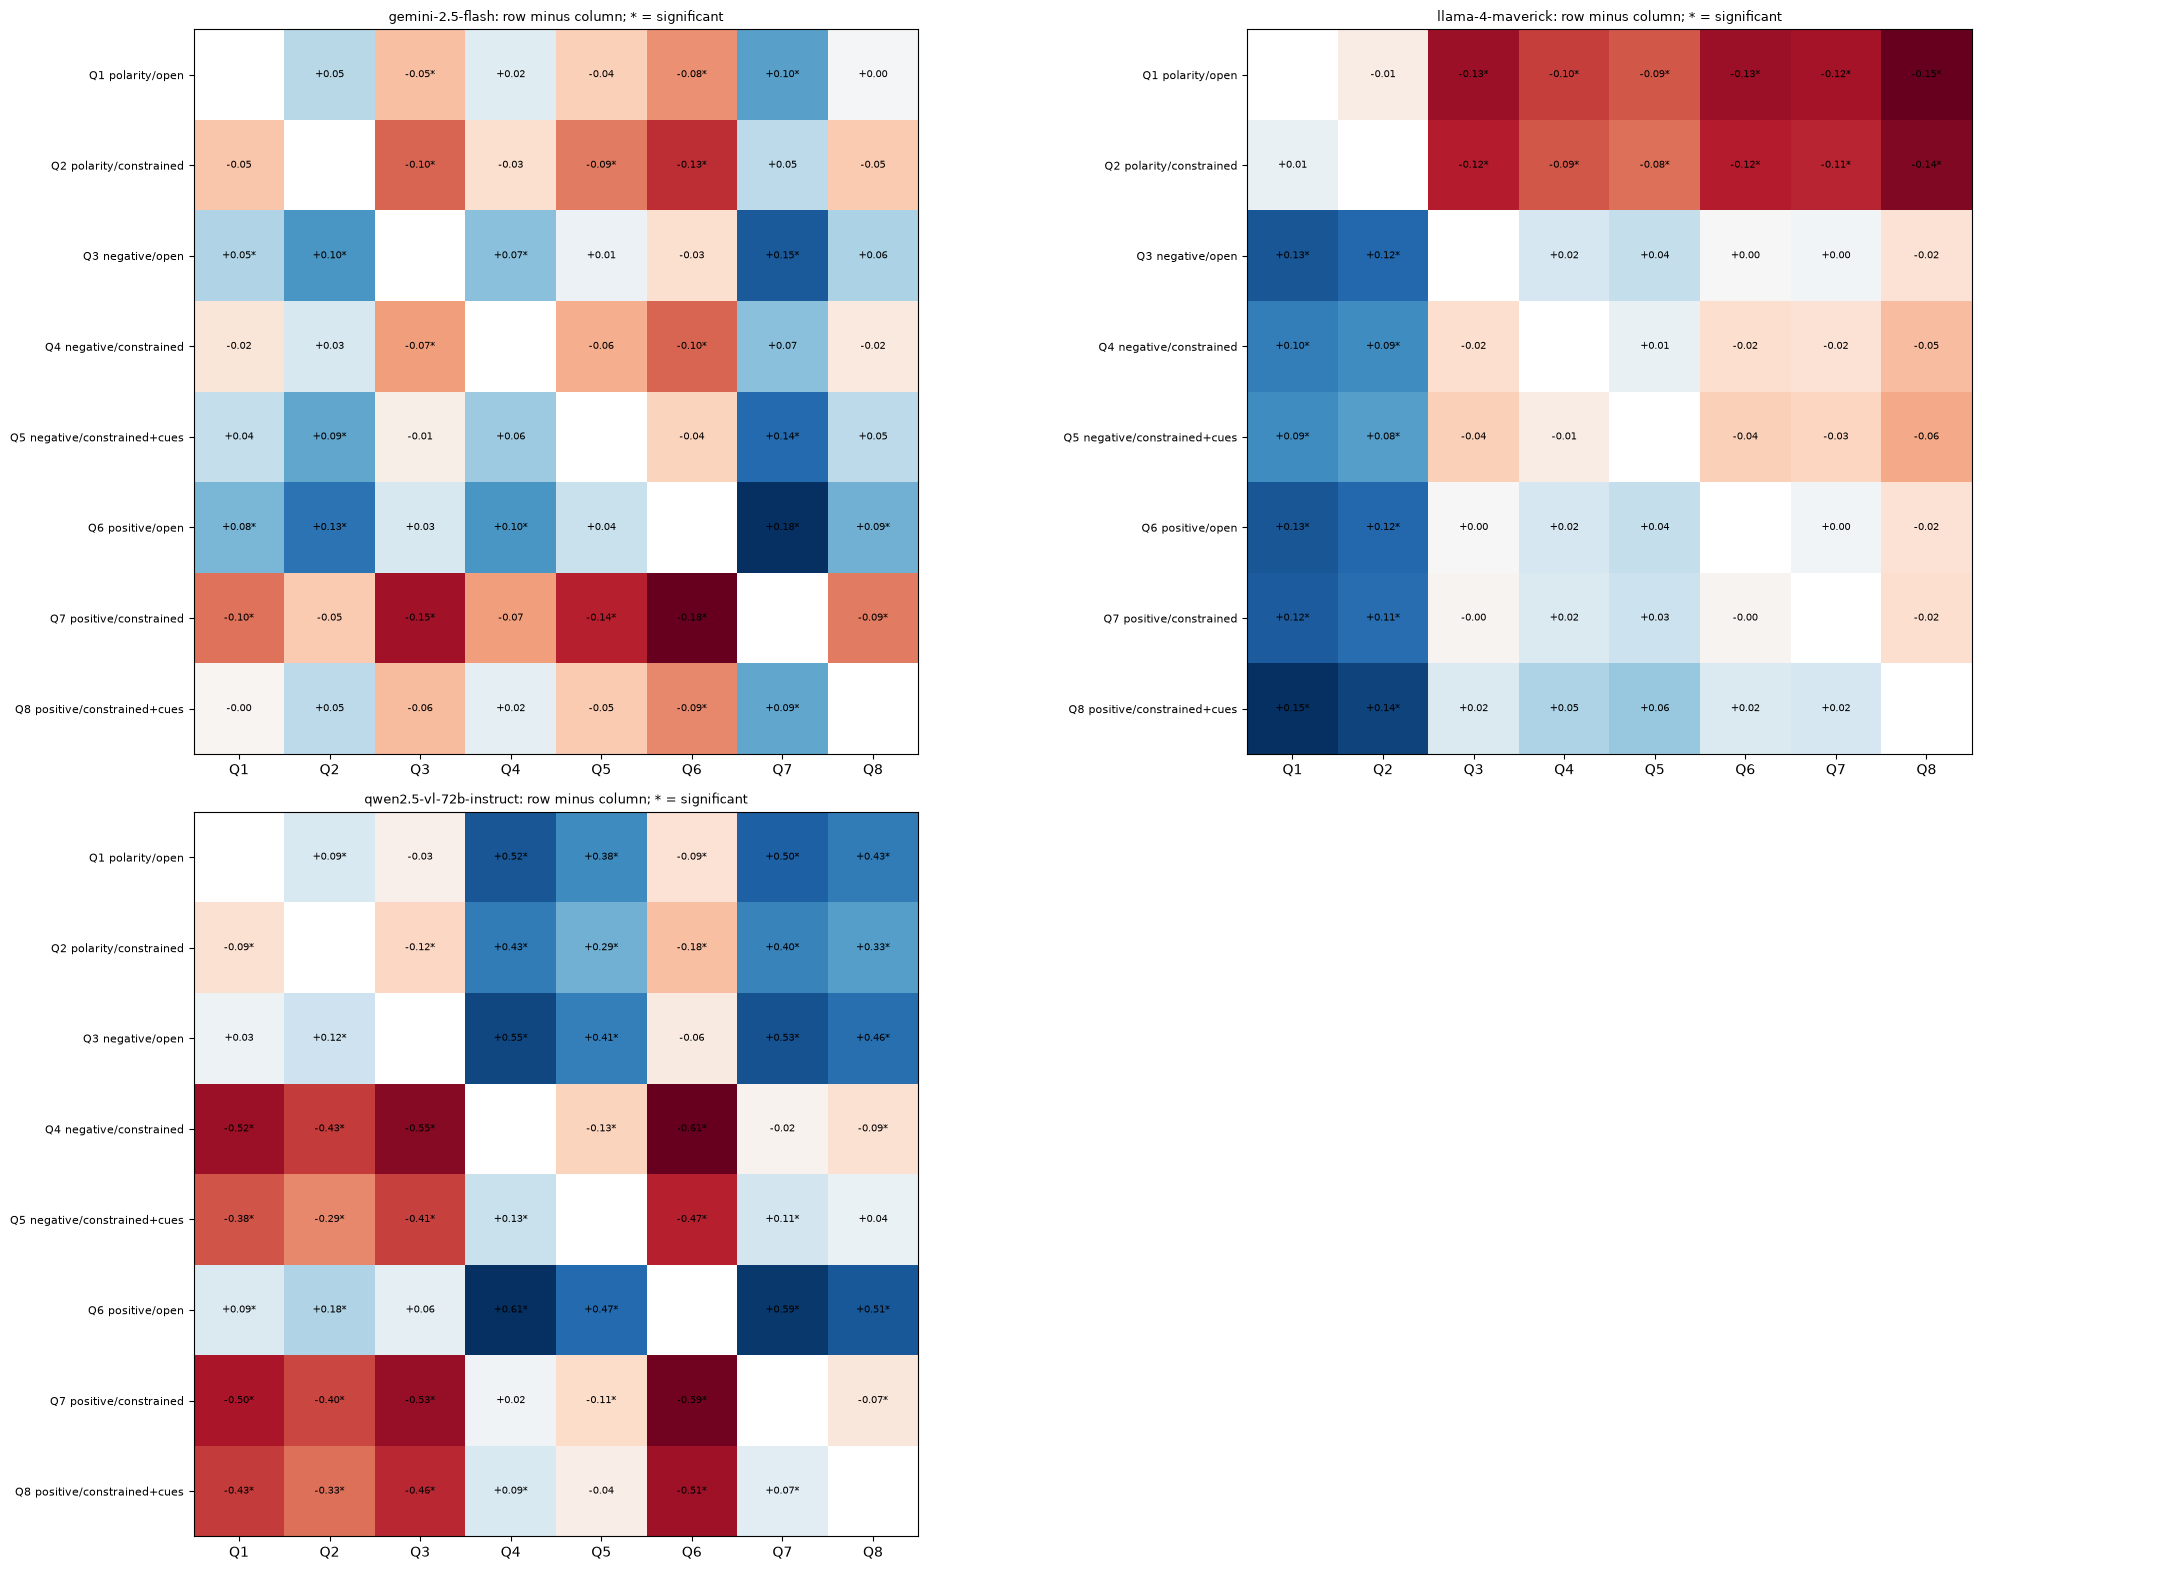

> **Result:** Significant question differences (of 28 pairs): gemini-2.5-flash 13, llama-4-maverick 12 and qwen2.5-vl-72b-instruct 24. 

In [16]:
tests = U.show_pairs(run)

## 5.6 Summary: which question to use?
The most accurate question per model and the questions that are not significantly worse. A question that is never significantly worse is a safe choice across models.

In [17]:
U.show_best(run, acc, tests)

,model,best_question,best_accuracy,not_significantly_worse,worst_question,worst_accuracy,mean_accuracy
0,gemini-2.5-flash,Q6,0.929,"Q3, Q5, Q6",Q7,0.752,0.848
1,llama-4-maverick,Q8,0.922,"Q3, Q4, Q5, Q6, Q7, Q8",Q1,0.773,0.865
2,qwen2.5-vl-72b-instruct,Q6,0.929,"Q3, Q6",Q4,0.323,0.616


> **Result:** Best question per model – gemini-2.5-flash: Q6 (0.93), llama-4-maverick: Q8 (0.92) and qwen2.5-vl-72b-instruct: Q6 (0.93). Q3 and Q6 are the best or not significantly worse than the best for every model, i.e. a safe choice across models.

## 5.7 Difficult images
How many answers go wrong per image, and the hardest images of each group. Errors on every question point to a hard image or a questionable label; errors on some questions point to the wording.

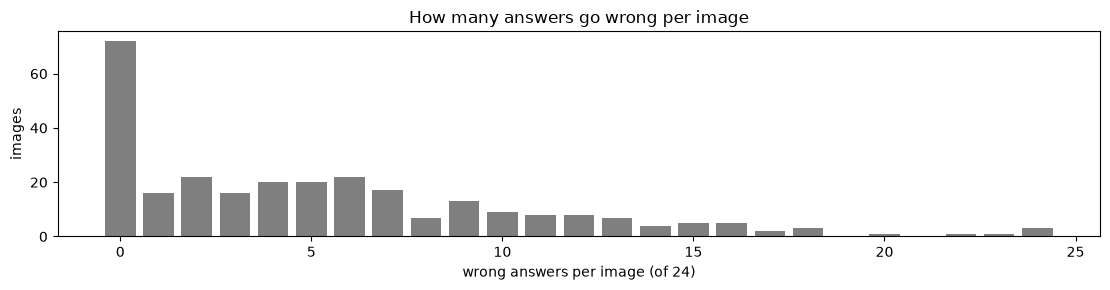

images  mean_share_wrong  hard_images (≥50% wrong)
group    subfolder                                                                    
positive neutral_vis_positive_text      10              0.73                        10
neutral  folder1                        40              0.34                         7
negative neutral_vis_negative_text      28              0.31                         7
positive folder2                        22              0.30                         5
neutral  folder2                        44              0.29                         3
negative nonviolent_2                    9              0.28                         2
         nonviolent_1                   19              0.26                         4
         violent_2                      10              0.17                         0
         violent_1                      33              0.05                         0
positive folder1                        67              0.04                         2

> **Result:** 72 of 282 images are answered correctly in all 24 answers, and 40 are wrong in half or more (17 positive, 13 negative, 10 neutral). The hardest group is neutral (32% wrong answers on average), the easiest positive (17%).

**Hardest images per group** – left: the image; right: expected answer (first row) and normalised answers, green = correct, red = wrong. Below: the raw wrong answers.

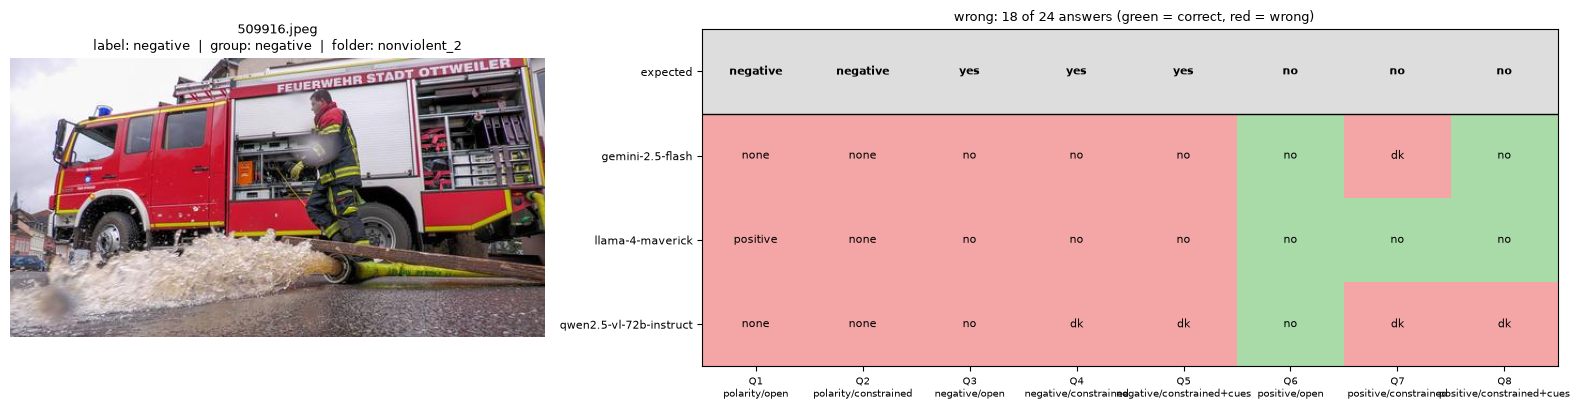

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,negative,none,"No, the picture does not show any explicit positive or negative emotional content. It depicts a scene of a firefighter working, which is a functional activity r"
1,llama-4-maverick,Q1,negative,positive,"The image depicts a firefighter in action, spraying water from a hose connected to a fire truck. The scene is set against a backdrop of a cloudy sky and buildin"
2,qwen2.5-vl-72b-instruct,Q1,negative,none,no
3,gemini-2.5-flash,Q2,negative,none,None.
4,llama-4-maverick,Q2,negative,none,none.
5,qwen2.5-vl-72b-instruct,Q2,negative,none,none
6,gemini-2.5-flash,Q3,yes,no,"No, the picture does not show any negative emotional content."
7,llama-4-maverick,Q3,yes,no,"No, the picture does not show any negative emotional content."
8,qwen2.5-vl-72b-instruct,Q3,yes,no,no
9,gemini-2.5-flash,Q4,yes,no,No.


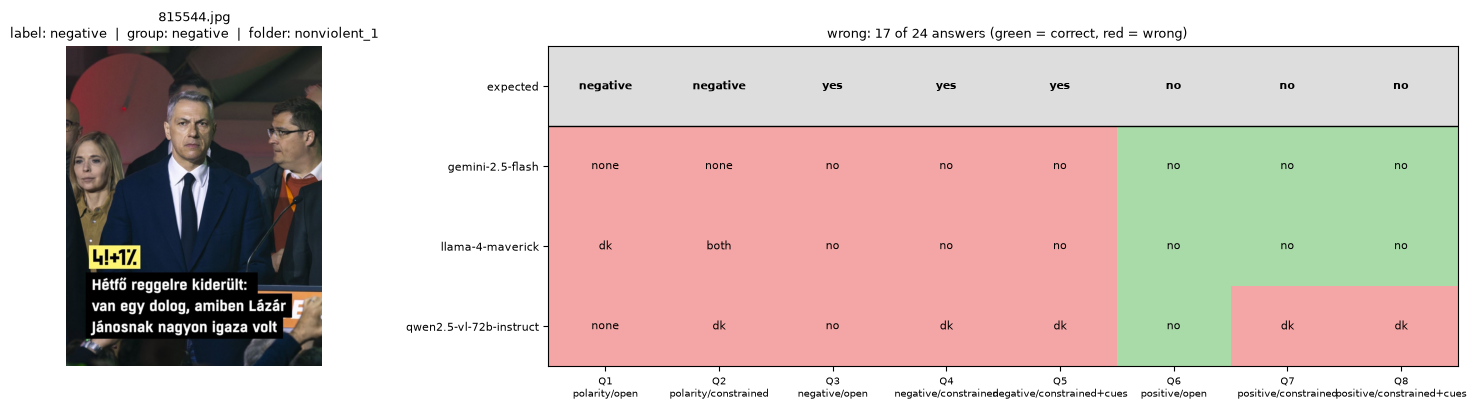

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,negative,none,The picture does not show any strong positive or negative emotional content. The people in the image have neutral expressions.
1,llama-4-maverick,Q1,negative,dk,"The image shows a man in a suit standing in front of microphones, surrounded by other people. The man's facial expression is neutral, but the overall atmosphere"
2,qwen2.5-vl-72b-instruct,Q1,negative,none,"The picture does not show any strong positive or negative emotional content. The individuals appear to be in a formal setting, possibly at a political event, an"
3,gemini-2.5-flash,Q2,negative,none,None
4,llama-4-maverick,Q2,negative,both,both.
5,qwen2.5-vl-72b-instruct,Q2,negative,dk,DK
6,gemini-2.5-flash,Q3,yes,no,"No, the picture does not show any negative emotional content. The people in the image appear to have neutral expressions."
7,llama-4-maverick,Q3,yes,no,"The image does not show any negative emotional content. The people in the image appear to be calm and neutral, with no visible signs of distress or negative emo"
8,qwen2.5-vl-72b-instruct,Q3,yes,no,No
9,gemini-2.5-flash,Q4,yes,no,No.


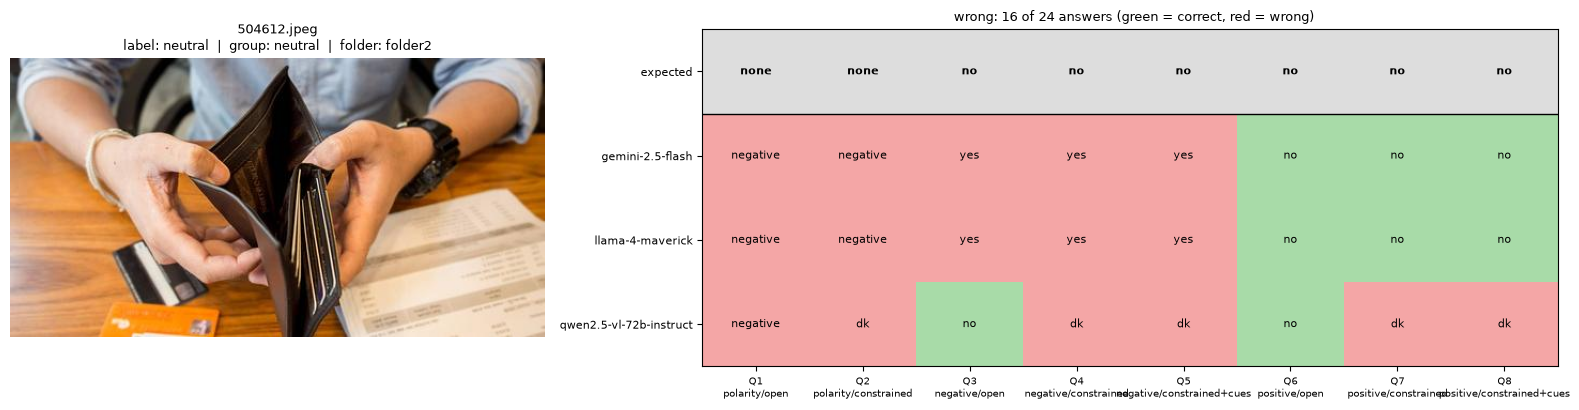

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,none,negative,Negative.
1,llama-4-maverick,Q1,none,negative,"The image depicts a person holding an empty wallet, which is often associated with financial difficulties or stress. The presence of bills on the table may sugg"
2,qwen2.5-vl-72b-instruct,Q1,none,negative,"The picture shows negative emotional content. The person appears to be holding an empty wallet, which typically symbolizes financial stress or lack of money. Th"
3,gemini-2.5-flash,Q2,none,negative,Negative
4,llama-4-maverick,Q2,none,negative,negative.
5,qwen2.5-vl-72b-instruct,Q2,none,dk,DK
6,gemini-2.5-flash,Q3,no,yes,"Yes, the picture shows negative emotional content. The person is holding an empty wallet, which typically signifies financial distress, worry, or disappointment"
7,llama-4-maverick,Q3,no,yes,"The image depicts a person holding an empty wallet, with a few bills visible inside. The presence of bills and cards on the table suggests that the individual i"
8,gemini-2.5-flash,Q4,no,yes,Yes.
9,llama-4-maverick,Q4,no,yes,yes


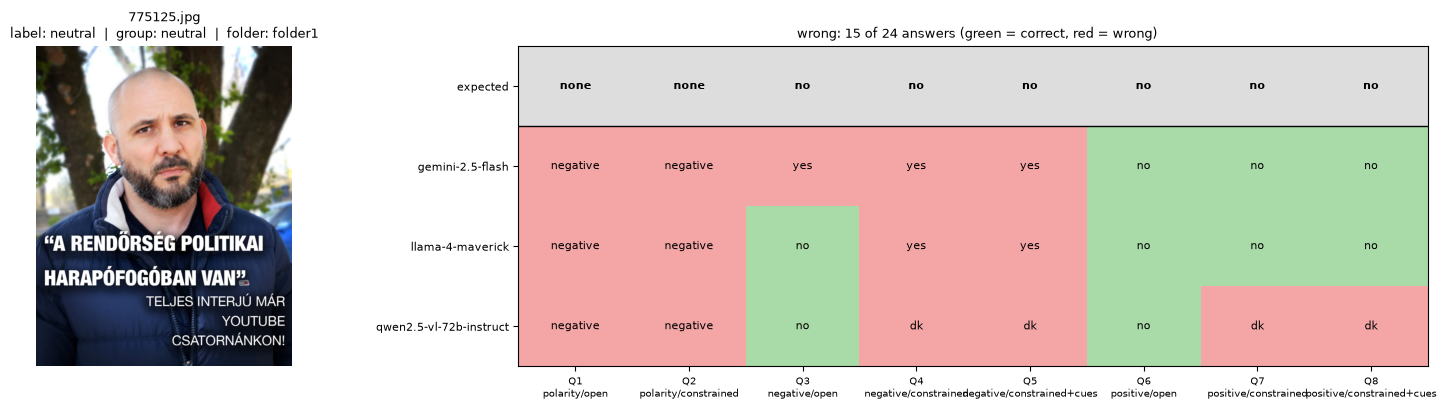

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,none,negative,"The man in the picture appears to be expressing a **negative** emotional content. His eyebrows are slightly furrowed, and his mouth is set in a somewhat serious"
1,llama-4-maverick,Q1,none,negative,"The image shows a man with a serious expression, and the text overlay appears to be a statement or quote in Hungarian. The overall tone of the image is negative"
2,qwen2.5-vl-72b-instruct,Q1,none,negative,"The picture shows negative emotional content. The man's expression appears serious and concerned, which aligns with the critical statement about the police bein"
3,gemini-2.5-flash,Q2,none,negative,Negative.
4,llama-4-maverick,Q2,none,negative,"The image conveys a negative emotional tone. The text in the image, written in Hungarian, is superimposed over a photograph of a man with a serious expression."
5,qwen2.5-vl-72b-instruct,Q2,none,negative,negative
6,gemini-2.5-flash,Q3,no,yes,"Yes, the man in the picture appears to be expressing a negative emotional content, specifically **concern** or **seriousness**, through his facial expression."
7,gemini-2.5-flash,Q4,no,yes,Yes.
8,llama-4-maverick,Q4,no,yes,Yes.
9,qwen2.5-vl-72b-instruct,Q4,no,dk,DK


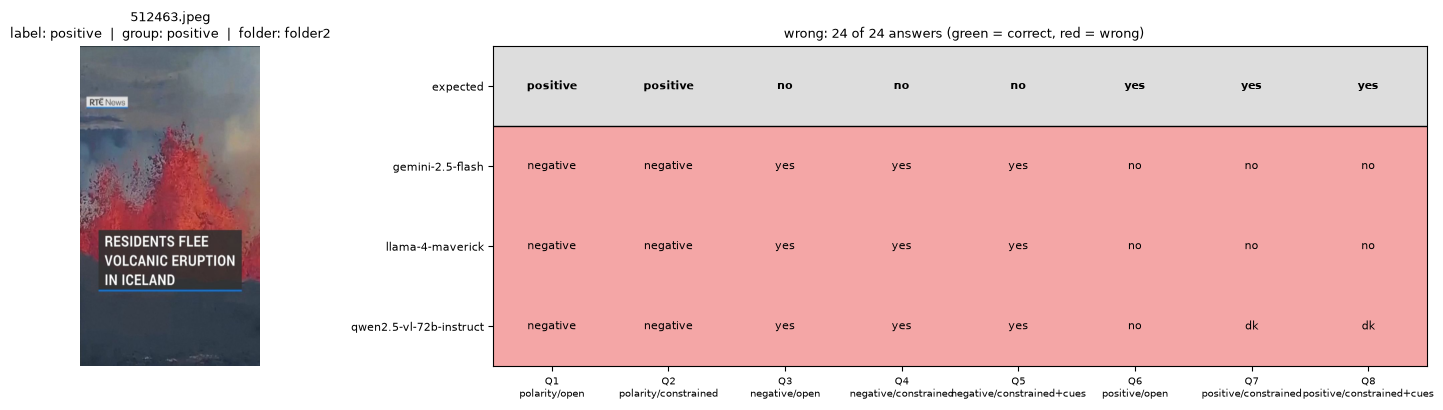

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,positive,negative,Negative.
1,llama-4-maverick,Q1,positive,negative,"The image depicts a volcanic eruption, which is a negative and potentially dangerous event. The text ""RESIDENTS FLEE VOLCANIC ERUPTION IN ICELAND"" suggests that"
2,qwen2.5-vl-72b-instruct,Q1,positive,negative,"The picture shows negative emotional content, as it depicts a volcanic eruption causing residents to flee, which is a dangerous and distressing situation."
3,gemini-2.5-flash,Q2,positive,negative,Negative.
4,llama-4-maverick,Q2,positive,negative,"The image depicts a volcanic eruption, with the text ""RESIDENTS FLEE VOLCANIC ERUPTION IN ICELAND"" overlaid on it. The scene is dramatic and intense, conveying"
5,qwen2.5-vl-72b-instruct,Q2,positive,negative,negative
6,gemini-2.5-flash,Q3,no,yes,"Yes, the picture shows negative emotional content. The text overlay ""RESIDENTS FLEE VOLCANIC ERUPTION IN ICELAND"" indicates a dangerous and distressing situatio"
7,llama-4-maverick,Q3,no,yes,"The image depicts a volcanic eruption, which is a potentially destructive and dangerous event. The presence of the text ""RESIDENTS FLEE VOLCANIC ERUPTION IN ICE"
8,qwen2.5-vl-72b-instruct,Q3,no,yes,Yes
9,gemini-2.5-flash,Q4,no,yes,Yes.


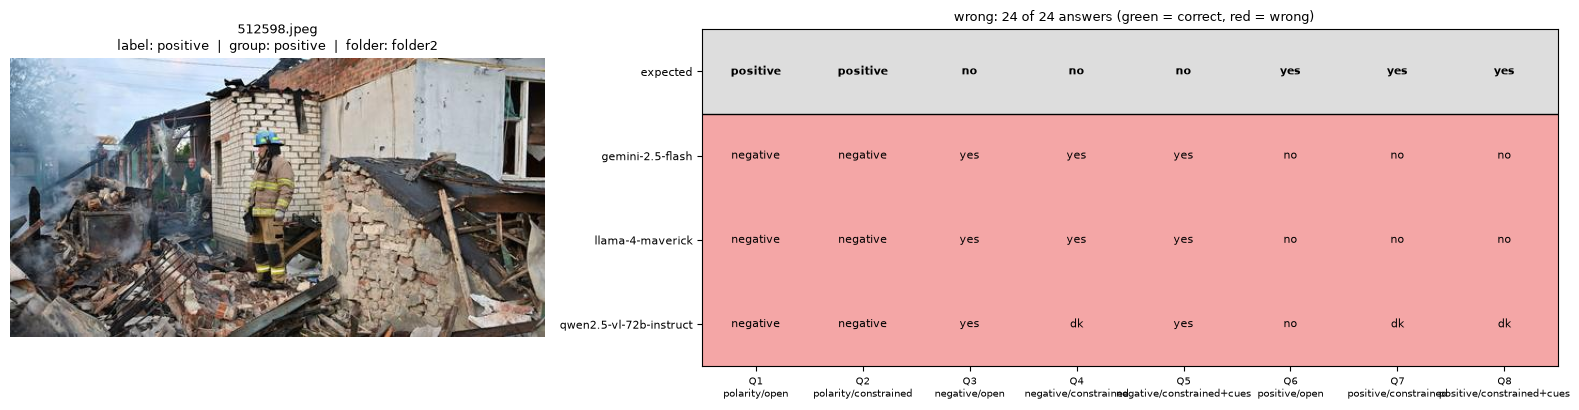

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,positive,negative,Negative.
1,llama-4-maverick,Q1,positive,negative,"The image depicts a firefighter standing amidst the ruins of a building, surrounded by debris and smoke. The scene is one of destruction and chaos, evoking feel"
2,qwen2.5-vl-72b-instruct,Q1,positive,negative,"The picture shows negative emotional content, depicting destruction and emergency response."
3,gemini-2.5-flash,Q2,positive,negative,Negative.
4,llama-4-maverick,Q2,positive,negative,negative.
5,qwen2.5-vl-72b-instruct,Q2,positive,negative,negative
6,gemini-2.5-flash,Q3,no,yes,"Yes, the picture shows negative emotional content."
7,llama-4-maverick,Q3,no,yes,"Yes, the picture shows negative emotional content. The image depicts a firefighter standing amidst the ruins of a building that has been severely damaged by fir"
8,qwen2.5-vl-72b-instruct,Q3,no,yes,Yes
9,gemini-2.5-flash,Q4,no,yes,Yes.


> **Result:** `509916.jpeg` (negative): 18 of 24 answers wrong by qwen2.5-vl-72b-instruct, gemini-2.5-flash and llama-4-maverick; most often "no" instead of "yes" (7x).<br>`815544.jpg` (negative): 17 of 24 answers wrong by qwen2.5-vl-72b-instruct, gemini-2.5-flash and llama-4-maverick; most often "no" instead of "yes" (7x).<br>`504612.jpeg` (neutral): 16 of 24 answers wrong by qwen2.5-vl-72b-instruct, gemini-2.5-flash and llama-4-maverick; most often "yes" instead of "no" (6x).<br>`775125.jpg` (neutral): 15 of 24 answers wrong by qwen2.5-vl-72b-instruct, gemini-2.5-flash and llama-4-maverick; most often "negative" instead of "none" (6x).<br>`512463.jpeg` (positive): 24 of 24 answers wrong by gemini-2.5-flash, llama-4-maverick and qwen2.5-vl-72b-instruct; most often "yes" instead of "no" (9x).<br>`512598.jpeg` (positive): 24 of 24 answers wrong by gemini-2.5-flash, llama-4-maverick and qwen2.5-vl-72b-instruct; most often "yes" instead of "no" (8x).<br>Look at the images: errors on every question point to a hard image or a questionable label, errors on some questions to the wording.

In [18]:
U.show_difficult_images(run)